# Praktikum 3: Classification dengan Ensemble Method & Class Imbalance

## 0. Import library

In [4]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [5]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
)
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)

## 1. Load dataset

In [6]:
DATA = "/kaggle/input/datasets/lioneiltrystan/creditcard/creditcard.csv"
df = pd.read_csv(DATA)

## 2. EDA

In [7]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [8]:
print(df.shape)
df.info()

(284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 2

### 2.1. Pemeriksaan awal

In [9]:
print("Jumlah missing value:", df.isna().sum().sum())
print("Jumlah baris duplikat:", df.duplicated().sum())
print("Kolom target tersedia:", "Class" in df.columns)

# Identifikasi missing value
if df.isna().any().any():
    print("\nKolom dengan missing value:")
    print(df.isna().sum()[df.isna().sum() > 0])

print("\nDistribusi target termasuk missing value:")
print(df["Class"].value_counts(dropna=False))

Jumlah missing value: 0
Jumlah baris duplikat: 1081
Kolom target tersedia: True

Distribusi target termasuk missing value:
Class
0    284315
1       492
Name: count, dtype: int64


,Jumlah,Persentase (%)
Normal (Class = 0),284315,99.827251
Fraud (Class = 1),492,0.172749


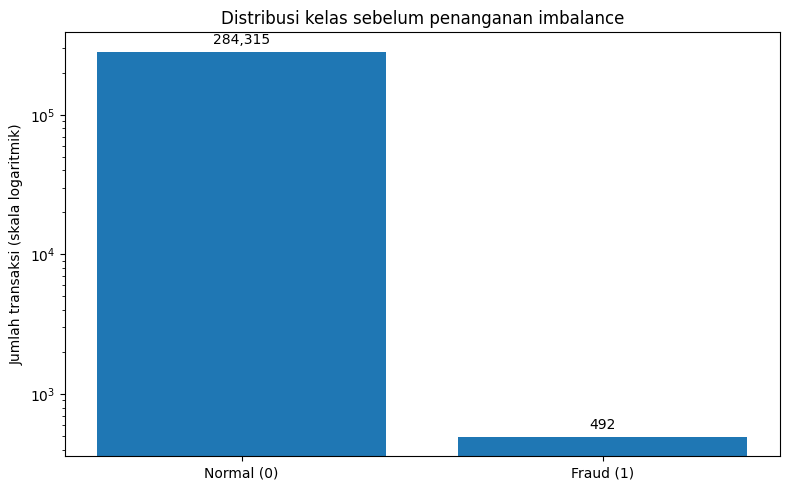

Proporsi kelas fraud: 0.1727%


In [10]:
class_counts = df["Class"].value_counts().reindex([0, 1], fill_value=0)
class_percentages = df["Class"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100

distribution_df = pd.DataFrame({
    "Jumlah": class_counts,
    "Persentase (%)": class_percentages,
})
distribution_df.index = ["Normal (Class = 0)", "Fraud (Class = 1)"]
display(distribution_df)

plt.figure(figsize=(8, 5))
labels = ["Normal (0)", "Fraud (1)"]
plt.bar(labels, class_counts.values)
plt.yscale("log")
plt.ylabel("Jumlah transaksi (skala logaritmik)")
plt.title("Distribusi kelas sebelum penanganan imbalance")
for i, value in enumerate(class_counts.values):
    plt.text(i, value * 1.08, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(f"Proporsi kelas fraud: {class_percentages.loc[1]:.4f}%")

## 3. Preprocessing


In [11]:
X = df.drop(columns="Class")
y = df["Class"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("\nDistribusi label data latih:")
display(y_train.value_counts().sort_index().rename(index={0: "Normal (0)", 1: "Fraud (1)"}).to_frame("Jumlah"))
print("Distribusi label data uji:")
display(y_test.value_counts().sort_index().rename(index={0: "Normal (0)", 1: "Fraud (1)"}).to_frame("Jumlah"))

# Pastikan stratifikasi mempertahankan proporsi label pada train dan test.
print(f"Proporsi fraud train: {y_train.mean() * 100:.4f}%")
print(f"Proporsi fraud test : {y_test.mean() * 100:.4f}%")

Ukuran X_train: (227845, 30)
Ukuran X_test : (56962, 30)

Distribusi label data latih:


,Jumlah
Class,
Normal (0),227451
Fraud (1),394


Distribusi label data uji:


,Jumlah
Class,
Normal (0),56864
Fraud (1),98


Proporsi fraud train: 0.1729%
Proporsi fraud test : 0.1720%


## 4. Random Forest tanpa penanganan class imbalance

In [12]:
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=2,
)

rf_baseline.fit(X_train, y_train)
print("Training Random Forest baseline selesai.")

Training Random Forest baseline selesai.


In [13]:
y_pred_baseline = rf_baseline.predict(X_test)
y_score_baseline = rf_baseline.predict_proba(X_test)[:, 1]

baseline_metrics = {
    "Model": "Random Forest - tanpa resampling",
    "Accuracy": accuracy_score(y_test, y_pred_baseline),
    "Precision": precision_score(y_test, y_pred_baseline, zero_division=0),
    "Recall": recall_score(y_test, y_pred_baseline, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_baseline, zero_division=0),
    "AUC-ROC": roc_auc_score(y_test, y_score_baseline),
}

display(pd.DataFrame([baseline_metrics]).set_index("Model").round(4))
print("Classification report — baseline:")
print(classification_report(
    y_test,
    y_pred_baseline,
    labels=[0, 1],
    target_names=["Normal (0)", "Fraud (1)"],
    digits=4,
    zero_division=0,
))

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Model,,,,,
Random Forest - tanpa resampling,0.9996,0.9412,0.8163,0.8743,0.963


Classification report — baseline:
              precision    recall  f1-score   support

  Normal (0)     0.9997    0.9999    0.9998     56864
   Fraud (1)     0.9412    0.8163    0.8743        98

    accuracy                         0.9996     56962
   macro avg     0.9704    0.9081    0.9371     56962
weighted avg     0.9996    0.9996    0.9996     56962



## 5. Menangani class imbalance dengan SMOTE

In [14]:
print("Distribusi data latih sebelum SMOTE:")
display(y_train.value_counts().sort_index().rename(index={0: "Normal (0)", 1: "Fraud (1)"}).to_frame("Jumlah"))

smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Distribusi data latih setelah SMOTE:")
display(y_train_smote.value_counts().sort_index().rename(index={0: "Normal (0)", 1: "Fraud (1)"}).to_frame("Jumlah"))
print("Shape X_train sebelum SMOTE:", X_train.shape)
print("Shape X_train setelah SMOTE :", X_train_smote.shape)
print("Shape data uji (tetap)       :", X_test.shape)

Distribusi data latih sebelum SMOTE:


,Jumlah
Class,
Normal (0),227451
Fraud (1),394


Distribusi data latih setelah SMOTE:


,Jumlah
Class,
Normal (0),227451
Fraud (1),227451


Shape X_train sebelum SMOTE: (227845, 30)
Shape X_train setelah SMOTE : (454902, 30)
Shape data uji (tetap)       : (56962, 30)


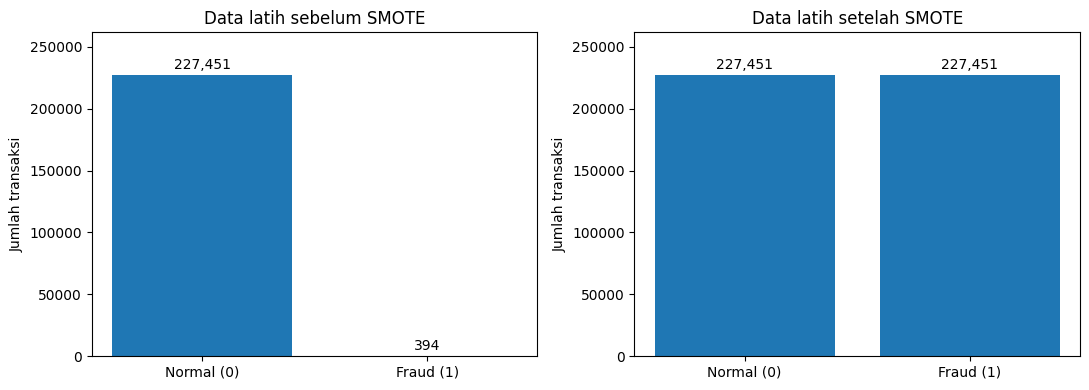

In [15]:
before_smote = y_train.value_counts().reindex([0, 1], fill_value=0)
after_smote = y_train_smote.value_counts().reindex([0, 1], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, counts, title in [
    (axes[0], before_smote, "Data latih sebelum SMOTE"),
    (axes[1], after_smote, "Data latih setelah SMOTE"),
]:
    ax.bar(["Normal (0)", "Fraud (1)"], counts.values)
    ax.set_title(title)
    ax.set_ylabel("Jumlah transaksi")
    for j, value in enumerate(counts.values):
        ax.text(j, value + max(counts.values) * 0.02, f"{value:,}", ha="center")
    ax.set_ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.show()

## 6. Random Forest setelah SMOTE

In [16]:
rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=2,
)

rf_smote.fit(X_train_smote, y_train_smote)
print("Training Random Forest + SMOTE selesai.")

Training Random Forest + SMOTE selesai.


In [17]:
y_pred_smote = rf_smote.predict(X_test)
y_score_smote = rf_smote.predict_proba(X_test)[:, 1]

smote_metrics = {
    "Model": "Random Forest + SMOTE",
    "Accuracy": accuracy_score(y_test, y_pred_smote),
    "Precision": precision_score(y_test, y_pred_smote, zero_division=0),
    "Recall": recall_score(y_test, y_pred_smote, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_smote, zero_division=0),
    "AUC-ROC": roc_auc_score(y_test, y_score_smote),
}

display(pd.DataFrame([smote_metrics]).set_index("Model").round(4))
print("Classification report — Random Forest + SMOTE:")
print(classification_report(
    y_test,
    y_pred_smote,
    labels=[0, 1],
    target_names=["Normal (0)", "Fraud (1)"],
    digits=4,
    zero_division=0,
))

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Model,,,,,
Random Forest + SMOTE,0.9994,0.8265,0.8265,0.8265,0.9644


Classification report — Random Forest + SMOTE:
              precision    recall  f1-score   support

  Normal (0)     0.9997    0.9997    0.9997     56864
   Fraud (1)     0.8265    0.8265    0.8265        98

    accuracy                         0.9994     56962
   macro avg     0.9131    0.9131    0.9131     56962
weighted avg     0.9994    0.9994    0.9994     56962



## 7. Evaluasi menggunakan confusion matrix

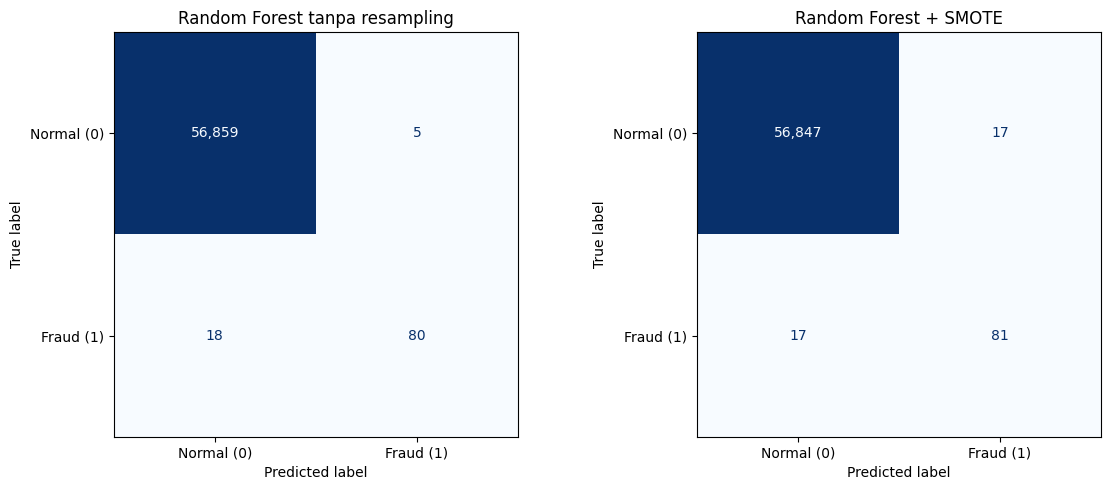

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_baseline,
    labels=[0, 1],
    display_labels=["Normal (0)", "Fraud (1)"],
    cmap="Blues", values_format=",d", ax=axes[0], colorbar=False,
)
axes[0].set_title("Random Forest tanpa resampling")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_smote,
    labels=[0, 1],
    display_labels=["Normal (0)", "Fraud (1)"],
    cmap="Blues", values_format=",d", ax=axes[1], colorbar=False,
)
axes[1].set_title("Random Forest + SMOTE")

plt.tight_layout()
plt.show()

## 8. Evaluasi menggunakan ROC curve dan AUC-ROC

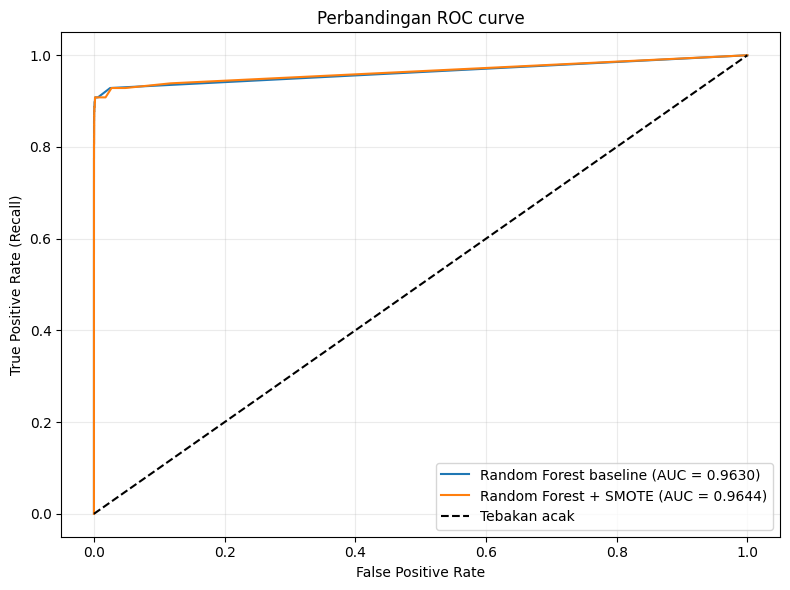

In [19]:
fpr_baseline, tpr_baseline, _ = roc_curve(y_test, y_score_baseline)
fpr_smote, tpr_smote, _ = roc_curve(y_test, y_score_smote)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr_baseline, tpr_baseline,
    label=f"Random Forest baseline (AUC = {baseline_metrics['AUC-ROC']:.4f})",
)
plt.plot(
    fpr_smote, tpr_smote,
    label=f"Random Forest + SMOTE (AUC = {smote_metrics['AUC-ROC']:.4f})",
)
plt.plot([0, 1], [0, 1], "k--", label="Tebakan acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Perbandingan ROC curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Perbandingan hasil kedua model

In [20]:
comparison_df = pd.DataFrame([baseline_metrics, smote_metrics]).set_index("Model")
comparison_df = comparison_df[["Accuracy", "Precision", "Recall", "F1-score", "AUC-ROC"]]
display(comparison_df.round(4))

print("Perubahan metrik setelah SMOTE (Random Forest + SMOTE dikurangi baseline):")
metric_delta = comparison_df.loc["Random Forest + SMOTE"] - comparison_df.loc["Random Forest - tanpa resampling"]
display(metric_delta.to_frame("Perubahan").round(4))

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Model,,,,,
Random Forest - tanpa resampling,0.9996,0.9412,0.8163,0.8743,0.9630
Random Forest + SMOTE,0.9994,0.8265,0.8265,0.8265,0.9644


Perubahan metrik setelah SMOTE (Random Forest + SMOTE dikurangi baseline):


,Perubahan
Accuracy,-0.0002
Precision,-0.1146
Recall,0.0102
F1-score,-0.0478
AUC-ROC,0.0014


- **Accuracy** saja tidak cukup untuk mengevaluasi model karena distribusi kelasnya sangat tidak seimbang. Jumlah transaksi normal jauh lebih banyak dibandingkan transaksi fraud. Akibatnya, model yang selalu memprediksi transaksi sebagai normal dapat memperoleh accuracy yang sangat tinggi, tetapi gagal mendeteksi transaksi fraud. Oleh karena itu, diperlukan metrik lain seperti precision, recall, F1-score, dan AUC-ROC untuk mengevaluasi kemampuan model dalam mendeteksi fraud secara lebih baik.